In [1]:
import autorootcwd
from src.models.components.backbone.wdcnn import WDCNN
import torch
import pandas as pd
from src.data.transforms.signal_representations import get_fft, get_fft_torch, get_envelope
from src.data.data_splits import cwru_leakage, paderborn_leakage
import matplotlib.pyplot as plt
from src.data.preprocess import segment_dataset

import torch.nn as nn
import torch.nn.functional as F
import numpy as np

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def get_group(row):

        if row["signal_location"] == "DE" and row["fault_location"] == "DE":
            if int(row["fault_size"]) == 7:
                if int(row["load"]) == 0:
                    return "A"
                elif int(row["load"]) == 1:
                    return "B"
                elif int(row["load"]) == 2:
                    return "C"
                elif int(row["load"]) == 3:
                    return "D"
            elif int(row["fault_size"]) == 14:
                if int(row["load"]) == 0:
                    return "E"
                elif int(row["load"]) == 1:
                    return "F"
                elif int(row["load"]) == 2:
                    return "G"
                elif int(row["load"]) == 3:
                    return "H"
            elif int(row["fault_size"]) == 21:
                if int(row["load"]) == 0:
                    return "I"
                elif int(row["load"]) == 1:
                    return "J"
                elif int(row["load"]) == 2:
                    return "K"
                elif int(row["load"]) == 3:
                    return "L"
        else:
            return "Z"

## CWRU

In [3]:
model_to_choose = "A"

model_path = f"data/saved_models/cwru/CWRULeakageNew_Time_LeakageSplit_no_leakage_80pct_TrainGroup_{model_to_choose}/last-v1.ckpt"
model_weights = torch.load(model_path, map_location=torch.device('cpu'), weights_only=False)


In [4]:
model_weights['state_dict'] = {k.replace('model.backbone.', ''): v for k, v in model_weights['state_dict'].items()}

In [5]:
model = WDCNN(in_channels=1, n_class=3, pretrained=False)
model.load_state_dict(model_weights['state_dict'])
model.eval()

def get_model_features(model, input_tensor):

    f1 = model.conv_layers(input_tensor)
    f2 = torch.flatten(f1, 1)
    f3 = F.relu(model.bn(model.fc(f2)))

    return f3

In [6]:
cwru = pd.read_pickle("data/datasets/cwru/processed/full_dataset.pkl")
filtered_cwru = pd.read_pickle("data/splits/cwru/filtered_cwru.pkl")

In [7]:
cwru = cwru[cwru.waveform_id.isin(filtered_cwru.waveform_id)]
cwru = cwru[(cwru.signal_location == "DE") & (cwru.fault_location == "DE")]

In [8]:
cwru.shape # 12 groups, 3 signals each, one from each class

(36, 18)

In [9]:
cwru_seg = segment_dataset(cwru, signal_column="signal", segment_size=12000)
cwru_seg['group'] = cwru_seg.apply(get_group, axis=1)

In [10]:
len_cwru = len(cwru)
# create len_cwru random integers between 0 and 108000
# set seed for reproducibility
np.random.seed(42)
random_integers = np.random.randint(0, 108000, size=len_cwru)
cwru.loc[:, 'random_seg'] = random_integers
cwru.loc[:, 'signal'] = cwru.apply(lambda row: row.signal[row.random_seg:row.random_seg+12000], axis=1)
cwru['group'] = cwru.apply(get_group, axis=1)

In [11]:
cwru.signal;

In [12]:
signals = cwru_seg.signal.values
signals = np.stack(signals) # 36 signals, each with 12000 samples
signals = torch.tensor(signals, dtype=torch.float32).unsqueeze(1) # add channel dimension
ffts = get_fft_torch(signals, axis=-1) # compute FFTs of the signals, shape (36, 1, 6000)

#signals = ffts

In [13]:
group1 = ["A", "B", "C", "D"]
group2 = ["E", "F", "G", "H"]
group3 = ["I", "J", "K", "L"]

inner_probas = torch.sigmoid(model(signals))[:, 0].detach().numpy()
outer_probas = torch.sigmoid(model(signals))[:, 1].detach().numpy()
ball_probas = torch.sigmoid(model(signals))[:, 2].detach().numpy()

print("Selecting model trained on group", model_to_choose, "(More steps)")

cwru_seg['inner_probas'] = inner_probas
cwru_seg['outer_probas'] = outer_probas
cwru_seg['ball_probas'] = ball_probas

# select group where 'model_to_choose' is located; remove 'model_to_choose' from the group
if model_to_choose in group1:
    group = group1.copy()
    group.remove(model_to_choose)
elif model_to_choose in group2:
    group = group2.copy()
    group.remove(model_to_choose)
elif model_to_choose in group3:
    group = group3.copy()
    group.remove(model_to_choose)

inner_labels = cwru_seg[cwru_seg.group.isin(group)].inner.values
outer_labels = cwru_seg[cwru_seg.group.isin(group)].outer.values
ball_labels = cwru_seg[cwru_seg.group.isin(group)].ball.values

ir_probas = cwru_seg[cwru_seg.group.isin(group)].inner_probas.values
outer_probas = cwru_seg[cwru_seg.group.isin(group)].outer_probas.values
ball_probas = cwru_seg[cwru_seg.group.isin(group)].ball_probas.values

print("Inner Score on condition-wise split:", roc_auc_score(inner_labels, ir_probas))
print("Outer Score on condition-wise split:", roc_auc_score(outer_labels, outer_probas))
print("Ball Score on condition-wise split:", roc_auc_score(ball_labels, ball_probas))

if model_to_choose in group1:
    group = group2 + group3
elif model_to_choose in group2:
    group = group1 + group3
elif model_to_choose in group3:
    group = group1 + group2

inner_labels = cwru_seg[cwru_seg.group.isin(group)].inner.values
outer_labels = cwru_seg[cwru_seg.group.isin(group)].outer.values
ball_labels = cwru_seg[cwru_seg.group.isin(group)].ball.values

ir_probas = cwru_seg[cwru_seg.group.isin(group)].inner_probas.values
outer_probas = cwru_seg[cwru_seg.group.isin(group)].outer_probas.values
ball_probas = cwru_seg[cwru_seg.group.isin(group)].ball_probas.values

inner_labels.shape, ir_probas.shape
print("Inner Score on no-leakage split:", roc_auc_score(inner_labels, ir_probas))
print("Outer Score on no-leakage split:", roc_auc_score(outer_labels, outer_probas))
print("Ball Score on no-leakage split:", roc_auc_score(ball_labels, ball_probas))

Selecting model trained on group A (More steps)
Inner Score on condition-wise split: 1.0
Outer Score on condition-wise split: 1.0
Ball Score on condition-wise split: 1.0
Inner Score on no-leakage split: 0.9478906250000001
Outer Score on no-leakage split: 0.5392968749999999
Ball Score on no-leakage split: 0.78734375


In [14]:
thrs = [0.5, 0.5, 0.5]

In [15]:
signals = cwru.signal.values
signals = np.stack(signals) # 36 signals, each with 12000 samples
signals = torch.tensor(signals, dtype=torch.float32).unsqueeze(1) # add channel dimension
ffts = get_fft_torch(signals, axis=-1) # compute FFTs of the signals, shape (36, 1, 6000)

inner_probas = torch.sigmoid(model(signals))[:, 0].detach().numpy()
outer_probas = torch.sigmoid(model(signals))[:, 1].detach().numpy()
ball_probas = torch.sigmoid(model(signals))[:, 2].detach().numpy()

cwru['inner_probas'] = inner_probas
cwru['outer_probas'] = outer_probas
cwru['ball_probas'] = ball_probas

cwru['inner_pred'] = (cwru.inner_probas >= thrs[0]).astype(int)
cwru['outer_pred'] = (cwru.outer_probas >= thrs[1]).astype(int)
cwru['ball_pred'] = (cwru.ball_probas >= thrs[2]).astype(int)

#signals = ffts

features = get_model_features(model, signals).detach().numpy()
std = 1 
features = features / std

cwru['features'] = list(features)

In [16]:
lr = model.out.weight.detach().numpy()
lr_inner = lr[0] #/ std  
lr_outer = lr[1] #/ std
lr_ball = lr[2] #/ std

w = [f"W{i+1}" for i in range(features.shape[1])]
f = [f"F{i+1}" for i in range(features.shape[1])]

inner = np.argsort(np.abs(lr_inner))[::-1]
n_features = 30
lr_inner_sorted = lr_inner[inner][:n_features]
lr_outer_sorted = lr_outer[inner][:n_features]
lr_ball_sorted = lr_ball[inner][:n_features]

inner_sorted = np.argsort(lr_inner_sorted)[::-1]

lr_inner_sorted = lr_inner_sorted[inner_sorted]
lr_outer_sorted = lr_outer_sorted[inner_sorted]
lr_ball_sorted = lr_ball_sorted[inner_sorted]


In [17]:
all_weights = np.stack([lr_inner, lr_outer, lr_ball], axis=1).T

W = all_weights  # shape (3, 100)
k = 15

selected_idx = []

for cls in range(3):
    # indices of top-k by absolute value for this class
    idx = np.argsort(W[cls])[::-1][:k]
    print(idx.shape)
    selected_idx.append(idx)

selecteds_idx = np.unique(np.concatenate(selected_idx)) 
W_filt = W[:, selecteds_idx] 

ir_ = W_filt[0]
or_ = W_filt[1]
ball_ = W_filt[2]

w = np.array(w)[selecteds_idx]
f = np.array(f)[selecteds_idx]


(15,)
(15,)
(15,)


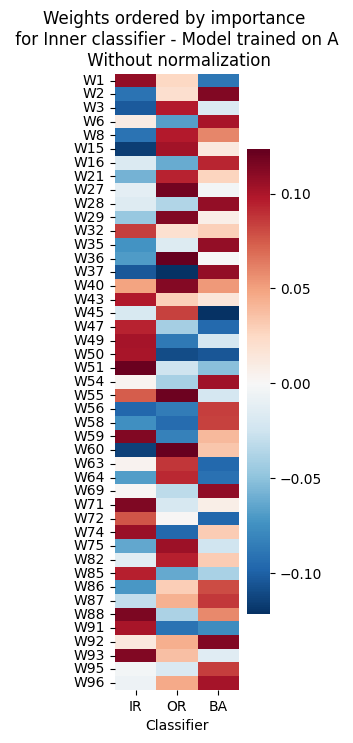

In [18]:

all_weights = np.stack([ir_, or_, ball_], axis=1)
#print(all_weights.shape)
plt.figure(figsize=(2, 8))
sns.heatmap((all_weights), cmap="RdBu_r", center=0,
            xticklabels=['IR', 'OR', 'BA'],
            yticklabels=w)

plt.title(f"Weights ordered by importance \n for Inner classifier - Model trained on {model_to_choose} \n Without normalization")
plt.xlabel("Classifier")
plt.show()


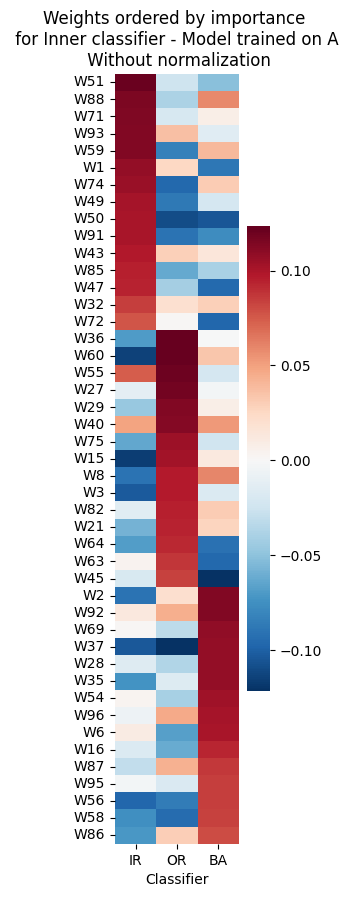

In [19]:
W = all_weights.T 

best_class = np.argmax(W, axis=0)     
best_weight = np.max(W, axis=0)          

valid = best_weight > 0

best_class = best_class[valid]
best_weight = best_weight[valid]
feature_idx = np.arange(W.shape[1])[valid]

ordered_idx = []

for cls in [0, 1, 2]:
    mask = best_class == cls
    cls_idx = feature_idx[mask]
    cls_weights = best_weight[mask]

    # sort descending by weight
    order = np.argsort(-cls_weights)
    ordered_idx.append(cls_idx[order])

ordered_idx = np.concatenate(ordered_idx)

new_weights = np.stack([all_weights.T[0][ordered_idx], all_weights.T[1][ordered_idx], all_weights.T[2][ordered_idx]], axis=1)


plt.figure(figsize=(2, 10))
sns.heatmap((new_weights), cmap="RdBu_r", center=0,
            xticklabels=['IR', 'OR', 'BA'],
            yticklabels=w[ordered_idx])

plt.title(f"Weights ordered by importance \n for Inner classifier - Model trained on {model_to_choose} \n Without normalization")
plt.xlabel("Classifier")
#plt.ylabel("Feature")
plt.show()


In [20]:
w = w[ordered_idx]
f = f[ordered_idx]
cwru['features_sorted'] = cwru.features.apply(lambda x: x[selecteds_idx][ordered_idx])

In [21]:
df = cwru.copy()
df['fault_type'] = df.apply(lambda row: 'OR' if 'OR' in row.fault_type else row.fault_type, axis=1)

df['bearing_id'] = df.apply(lambda row: f"{row.fault_type}_{row.fault_size}", axis=1)

p1 = df[df.bearing_id == "IR_7"].copy().sort_values(by="group", ascending=True)
p2 = df[df.bearing_id == "IR_14"].copy().sort_values(by="group", ascending=True)
p3 = df[df.bearing_id == "IR_21"].copy().sort_values(by="group", ascending=True)
p4 = df[df.bearing_id == "OR_7"].copy().sort_values(by="group", ascending=True)
p5 = df[df.bearing_id == "OR_14"].copy().sort_values(by="group", ascending=True)
p6 = df[df.bearing_id == "OR_21"].copy().sort_values(by="group", ascending=True)
p7 = df[df.bearing_id == "B_7"].copy().sort_values(by="group", ascending=True)
p8 = df[df.bearing_id == "B_14"].copy().sort_values(by="group", ascending=True)
p9 = df[df.bearing_id == "B_21"].copy().sort_values(by="group", ascending=True)

train_bearings = ["IR_7", "OR_7", "B_7"]
training_group = model_to_choose

df = pd.concat([p1, p2, p3, p4, p5, p6, p7, p8, p9])
df['subgroup'] = df.apply(lambda row: "Train signals" if (row.bearing_id in train_bearings) & (row.group == training_group) else "Condition-wise Test signals" if (row.bearing_id in train_bearings) & (row.group != training_group) else "No-leakage Test signals", axis=1)

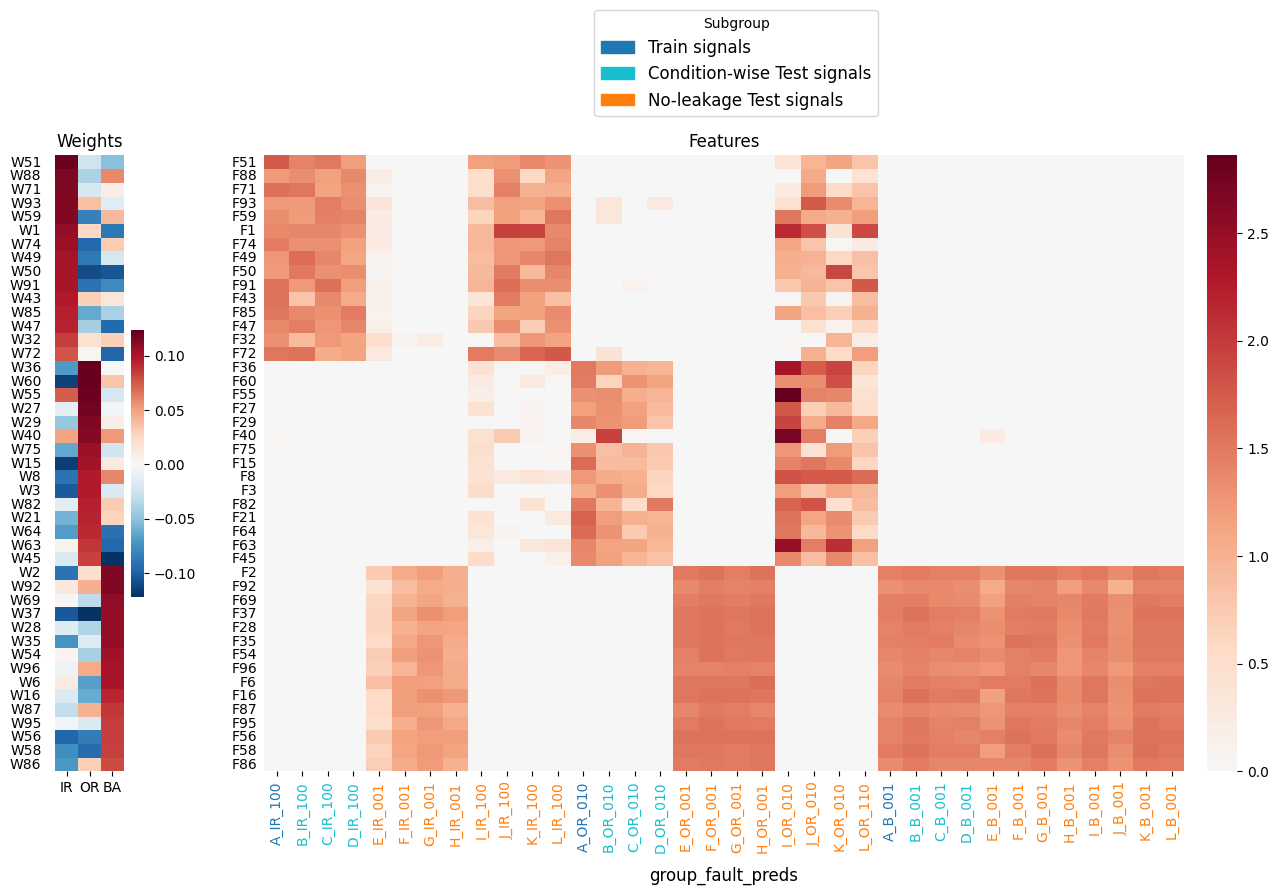

In [31]:
group_colors = {
    "Train signals": "#1f77b4",
    "Condition-wise Test signals": "#17becf",
    "No-leakage Test signals": "#ff7f0e",
}

fts = np.stack(df.features_sorted.values)
names = [f"{i}_{j}_{k}{l}{m}" for i, j, k, l,m in zip(df.group, df.fault_type, df.inner_pred, df.outer_pred, df.ball_pred)]

fig, (ax_w, ax_f) = plt.subplots(
    ncols=2,
    figsize=(17, 8),
    gridspec_kw={"width_ratios": [0.4, 5]},
    sharey=False
)

sns.heatmap(
    new_weights,
    cmap="RdBu_r",
    center=0,
    ax=ax_w,
    cbar=True,
    cbar_kws={"pad": 0.08},  # increase this value (default ~0.02)
    xticklabels=['IR', 'OR', 'BA'],
    yticklabels=w
)

ax_w.tick_params(axis='y', pad=10, length=0)

ax_w.set_title("Weights")
ax_f.set_title("Features")
ax_w.set_xlabel("")

sns.heatmap(
    fts.T,
    cmap="RdBu_r",
    center=0,
    ax=ax_f,
    xticklabels=names,
    yticklabels=f,
    cbar_kws={"pad": +0.02},

)

#ax_f.set_title(f"Feature contribution per signal (15 highest weights per fault classifier) \n Model trained in Group {model_to_choose} \n ")
ax_f.set_xlabel("group_fault_preds", labelpad=10, fontsize=12)
ax_f.set_xticklabels(ax_f.get_xticklabels(), fontsize=10)
ax_f.tick_params(axis='y', pad=5, length=0)

for tick_label, grp in zip(ax_f.get_xticklabels(), df.subgroup):
    tick_label.set_color(group_colors.get(grp, "black"))

from matplotlib.patches import Patch

legend_patches = [Patch(color=c, label=g) for g, c in group_colors.items()]
ax_f.legend(handles=legend_patches, title="Subgroup", bbox_to_anchor=(0.35, 1.25), loc="upper left", fontsize=12)

plt.savefig(
    "notebooks/cwru/feature_distribution_modelA.pdf",
    bbox_inches="tight",
    dpi=600,
    transparent=True,
)
plt.show()
